# Eurovision: прогноз топ-10 и победителя

| Модель | Полезность участника | Что проверяем |
|---|---|---|
| M0 | Историческая сила страны | Обучаемая точка отсчёта |
| M1 | Сила страны + признаки | Польза признаков |
| M2 | Те же признаки; иерархическая сила страны | Польза оцениваемого partial pooling |

Во всех трёх моделях используем **Plackett–Luce для полного рейтинга**.
M0/M1 имеют фиксированный масштаб prior силы стран; M2 оценивает общий масштаб.
**2025 — отдельный тест. Обучение и проверка настроек используют годы до 2025.**
Это ретроспективная оценка, а не прогноз, опубликованный до конкурса.


In [4]:
%pip -q install "numpyro==0.19.0" "jax[cpu]==0.7.2" "arviz==0.22.0" openpyxl


In [5]:
from pathlib import Path
from math import lgamma
from itertools import permutations
import hashlib
import json
import time
import warnings
import shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, MaxNLocator
from scipy.special import logsumexp, softmax
from scipy.stats import rankdata
from IPython.display import display, Markdown

import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import numpyro
import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS
import arviz as az

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data/eurovision_features.xlsx").is_file())
DATA_PATH = ROOT / "data/eurovision_features.xlsx"
EXPERIMENT =  "matched_core"  # market / matched_core / full_core
OUTPUT_DIR = ROOT / "results/generated/task_a" / EXPERIMENT
HOLDOUT_YEAR = 2025
SEED = 20261025
MODELS = ("M0", "M1", "M2")
COUNTRY_SD = 0.5
BETA_SD = 0.5
TAU_SD = 0.5
NUM_CHAINS, NUM_WARMUP, NUM_SAMPLES = 4, 1000, 1000
RANKINGS_PER_DRAW = 25
RUN_SENSITIVITY = True
MODEL_VERSION = "A-country-PL-v1"

CORE_FEATURES = [
    "running_position", "host", "english_only", "english_mixed", "bpm",
    "danceability", "dynamic_complexity", "log_word_count", "repetitiveness",
    "past_final_strength", "past_final_count",
]
BINARY_FEATURES = {"host", "english_only", "english_mixed"}
EXPERIMENTS = {
    "market": ("A С рынком", CORE_FEATURES + ["market_strength"], 2021),
    "matched_core": ("A С рынком", CORE_FEATURES, 2021),
    "full_core": ("A Топ-10", CORE_FEATURES, 2013),
}
if EXPERIMENT not in EXPERIMENTS:
    raise ValueError(f"Выберите эксперимент из {list(EXPERIMENTS)}")
SHEET, FEATURES, FIRST_TEST_YEAR = EXPERIMENTS[EXPERIMENT]
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
COLORS = {"M0": "#65758A", "M1": "#3569B8", "M2": "#168B83"}
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 11, "figure.dpi": 120,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "savefig.facecolor": "white",
})
pd.set_option("display.max_rows", 40)
pd.set_option("display.precision", 4)
print(f"NumPyro {numpyro.__version__}; JAX {jax.__version__}; ArviZ {az.__version__}")


NumPyro 0.19.0; JAX 0.7.2; ArviZ 0.22.0


## 1. Данные и временное разделение

По умолчанию `market`: единая выборка 2015–2025 с котировками.
`matched_core` исключает рыночный признак на **тех же наблюдениях**;
`full_core` использует всю историю с 2008 года без котировок.
Сравнивать вклад рынка можно между `market` и `matched_core`.
Время архивных котировок неизвестно — принятое ограничение рыночного эксперимента.

Стандартизацию учим заново только на тренировочных годах. Индикаторы 0/1 не масштабируем.
Итоги 2025 храним отдельно; функция прогноза получает только состав и признаки.


In [6]:
if not DATA_PATH.is_file():
    raise FileNotFoundError("Укажите путь к Excel в DATA_PATH и повторите запуск.")
raw = pd.read_excel(DATA_PATH, sheet_name=SHEET)
required = ["year", "country", "n_finalists", "place_final", "target_top10"] + FEATURES
missing = set(required) - set(raw.columns)
if missing:
    raise ValueError(f"Не хватает столбцов: {sorted(missing)}")
assert not raw[required].isna().any().any(), "В нужных столбцах есть пропуски"
assert not raw.duplicated(["year", "country"]).any(), "Повторяются участники"
assert np.isfinite(raw[FEATURES].to_numpy(float)).all()
assert not raw.year.eq(2020).any()
for year, g in raw.groupby("year"):
    assert g.n_finalists.eq(len(g)).all()
    assert sorted(g.place_final) == list(range(1, len(g) + 1))
    assert g.target_top10.eq(g.place_final.le(10).astype(int)).all()
for col in BINARY_FEATURES:
    assert raw[col].isin([0, 1]).all(), col
assert raw.year.max() == HOLDOUT_YEAR
development = raw.loc[raw.year.lt(HOLDOUT_YEAR)].copy()
holdout_design = raw.loc[raw.year.eq(HOLDOUT_YEAR), ["year", "country"] + FEATURES].copy()
holdout_truth = raw.loc[raw.year.eq(HOLDOUT_YEAR),
                        ["year", "country", "place_final", "target_top10"]].copy()
DEV_YEARS = sorted(y for y in development.year.unique() if y >= FIRST_TEST_YEAR)
expected = set(range(FIRST_TEST_YEAR, HOLDOUT_YEAR)) - {2020}
assert set(DEV_YEARS) == expected, "Пропущены годы проверки"


def prepare_fold(train, design):
    assert train.year.max() < design.year.min()
    assert train.year.max() < HOLDOUT_YEAR
    # Никаких итоговых мест или целевых меток в design.
    assert not {"place_final", "target_top10"} & set(design.columns)
    train = train.sort_values(["year", "place_final"]).copy()
    test = design.sort_values("country").reset_index(drop=True).copy()
    countries = sorted(train.country.unique())
    index = {c: i for i, c in enumerate(countries)}
    mean = train[FEATURES].mean()
    scale = train[FEATURES].std(ddof=0).replace(0, 1)
    mean.loc[list(BINARY_FEATURES)] = 0
    scale.loc[list(BINARY_FEATURES)] = 1
    x_train = (train[FEATURES] - mean) / scale
    x_test = ((test[FEATURES] - mean) / scale).to_numpy(float)
    years = sorted(train.year.unique())
    width = int(train.groupby("year").size().max())
    X = np.zeros((len(years), width, len(FEATURES)))
    country_idx = np.zeros((len(years), width), dtype=int)
    mask = np.zeros((len(years), width), dtype=bool)
    for i, year in enumerate(years):
        g = train.loc[train.year.eq(year)]
        n = len(g)
        X[i, :n] = x_train.loc[g.index].to_numpy(float)
        country_idx[i, :n] = g.country.map(index)
        mask[i, :n] = True
    return dict(X=X, country_idx=country_idx, mask=mask,
                countries=countries, index=index, x_test=x_test, test=test,
                train=train, mean=mean, scale=scale)


display(pd.DataFrame([
    {"period": "development", "years": f"{development.year.min()}–2024",
     "rows": len(development)},
    {"period": "holdout", "years": "2025", "rows": len(holdout_design)},
]))
print("Годы проверки до финального теста:", DEV_YEARS)
print("Признаки M1/M2:", ", ".join(FEATURES))


,period,years,rows
0,development,2015–2024,233
1,holdout,2025,26


Годы проверки до финального теста: [np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]
Признаки M1/M2: running_position, host, english_only, english_mixed, bpm, danceability, dynamic_complexity, log_word_count, repetitiveness, past_final_strength, past_final_count


## 2. Три модели одного полного рейтинга

Для наблюдаемого порядка $\pi$:
$$P(\pi\mid\eta)=\prod_{k=1}^{N-1}
\frac{\exp(\eta_{\pi_k})}{\sum_{j=k}^{N}\exp(\eta_{\pi_j})}.$$
M0: $\eta_i=a_{c(i)}$. M1/M2: $\eta_i=a_{c(i)}+x_i^\top\beta$.

M0/M1: исходные эффекты стран независимы, $u_c\sim N(0,0.5^2)$.
M2: $u_c=\tau z_c$, $z_c\sim N(0,1)$, $\tau\sim HalfNormal(0.5)$.
Во всех моделях центрируем эффекты: $a_c=u_c-\bar u$.
Для M1/M2: $\beta_j\sim N(0,0.5^2)$ после стандартизации.
Общий intercept не нужен: он сокращается в вероятностях рейтинга.


In [7]:
def pl_log_prob(eta, mask):
    """По одной log probability на полный финал; padding не является кандидатом."""
    safe = jnp.where(mask, eta, -1e30)
    denominators = jax.lax.associative_scan(
        jnp.logaddexp, safe[..., ::-1], axis=-1
    )[..., ::-1]
    return jnp.where(mask, safe - denominators, 0.0).sum(axis=-1)


def ranking_model(X, country_idx, mask, n_countries, model_id, prior_multiplier=1.0):
    z = numpyro.sample("z", dist.Normal(0, 1).expand([n_countries]).to_event(1))
    if model_id == "M2":
        sigma = numpyro.sample("tau", dist.HalfNormal(TAU_SD * prior_multiplier))
    else:
        sigma = COUNTRY_SD * prior_multiplier
    a = numpyro.deterministic("a", sigma * (z - z.mean()))
    eta = a[country_idx]
    if model_id != "M0":
        beta = numpyro.sample("beta", dist.Normal(0, BETA_SD * prior_multiplier)
                              .expand([X.shape[-1]]).to_event(1))
        eta = eta + X @ beta
    numpyro.factor("ranking", pl_log_prob(eta, mask).sum())


def predictive_utilities(samples, fold, model_id, rng, prior_multiplier=1.0):
    """В том числе интегрируем prior нового эффекта для незнакомой страны."""
    z = samples["z"]
    sigma = (samples["tau"] if model_id == "M2"
             else np.full(z.shape[:2], COUNTRY_SD * prior_multiplier))
    offsets = z.mean(axis=-1)
    eta = np.empty(z.shape[:2] + (len(fold["test"]),))
    for i, country in enumerate(fold["test"].country):
        effect = (z[..., fold["index"][country]] if country in fold["index"]
                  else rng.normal(size=z.shape[:2]))
        eta[..., i] = sigma * (effect - offsets)
    if model_id != "M0":
        eta += np.einsum("cdp,np->cdn", samples["beta"], fold["x_test"])
    return eta


## 3. Обучение и диагностика

Как в решённом HA4, используем NumPyro/NUTS и четыре цепи.
Требуем: $\hat R\le1.01$, bulk ESS ≥ 400, tail ESS ≥ 200,
отсутствие divergences и достижений предельной глубины дерева.
При проблеме один раз увеличиваем длину расчёта и точность интегратора.
Если повтор не помог, останавливаемся и сохраняем диагностику.
Проверки вычислений не используют качество на 2025.


In [8]:
def fit_posterior(fold, model_id, seed, prior_multiplier=1.0):
    settings = dict(model=model_id, prior_multiplier=prior_multiplier,
                    features=FEATURES, countries=fold["countries"], seed=int(seed),
                    country_sd=COUNTRY_SD, beta_sd=BETA_SD, tau_sd=TAU_SD,
                    chains=NUM_CHAINS, warmup=NUM_WARMUP, samples=NUM_SAMPLES,
                    model_version=MODEL_VERSION, numpyro=numpyro.__version__, jax=jax.__version__)
    signature = hashlib.sha256(json.dumps(settings, sort_keys=True).encode())
    signature.update(ranking_model.__code__.co_code)
    signature.update(repr(ranking_model.__code__.co_consts).encode())
    signature.update(pl_log_prob.__code__.co_code)
    signature.update(repr(pl_log_prob.__code__.co_consts).encode())
    for key in ("X", "country_idx", "mask"):
        signature.update(np.ascontiguousarray(fold[key]).tobytes())
    stem = f"{model_id}_{fold['test'].year.iloc[0]}_{signature.hexdigest()[:16]}"
    cache = OUTPUT_DIR / "posterior"
    cache.mkdir(exist_ok=True)
    npz, meta = cache / f"{stem}.npz", cache / f"{stem}.json"
    if npz.exists() and meta.exists():
        report = json.loads(meta.read_text())
        if report["passed"]:
            report["prior_multiplier"] = float(prior_multiplier)
            print(f"  {model_id}: проверенный posterior из сохранённого расчёта", flush=True)
            with np.load(npz, allow_pickle=False) as loaded:
                return {k: loaded[k] for k in loaded.files}, report
    for attempt in range(2):
        print(f"  {model_id}: NUTS, попытка {attempt + 1}", flush=True)
        kernel = NUTS(ranking_model, target_accept_prob=0.95 if attempt == 0 else 0.99,
                      max_tree_depth=10 if attempt == 0 else 12)
        mcmc = MCMC(kernel, num_warmup=NUM_WARMUP * (attempt + 1),
                    num_samples=NUM_SAMPLES * (attempt + 1), num_chains=NUM_CHAINS,
                    chain_method="sequential", progress_bar=True)
        started = time.perf_counter()
        mcmc.run(jax.random.PRNGKey(seed + attempt),
                 jnp.asarray(fold["X"]), jnp.asarray(fold["country_idx"]),
                 jnp.asarray(fold["mask"]), len(fold["countries"]), model_id,
                 prior_multiplier, extra_fields=("diverging", "num_steps"))
        samples = {k: np.asarray(v) for k, v in mcmc.get_samples(group_by_chain=True).items()}
        extra = mcmc.get_extra_fields(group_by_chain=True)
        diag = az.summary(az.from_dict(posterior=samples), kind="diagnostics", round_to=6)
        diag.to_csv(cache / f"{stem}_diagnostics.csv")
        depth_limit = 2 ** (10 if attempt == 0 else 12) - 1
        report = dict(model=model_id, year=int(fold["test"].year.iloc[0]),
                      prior_multiplier=float(prior_multiplier),
                      train_start=int(fold["train"].year.min()),
                      train_end=int(fold["train"].year.max()),
                      rhat_max=float(diag.r_hat.max()),
                      ess_bulk_min=float(diag.ess_bulk.min()),
                      ess_tail_min=float(diag.ess_tail.min()),
                      divergences=int(np.asarray(extra["diverging"]).sum()),
                      max_depth_hits=int((np.asarray(extra["num_steps"]) >= depth_limit).sum()),
                      seconds=time.perf_counter() - started, attempt=attempt + 1)
        report["passed"] = bool(
            np.isfinite(diag[["r_hat", "ess_bulk", "ess_tail"]]).all().all()
            and report["rhat_max"] <= 1.01 and report["ess_bulk_min"] >= 400
            and report["ess_tail_min"] >= 200 and report["divergences"] == 0
            and report["max_depth_hits"] == 0)
        meta.write_text(json.dumps(report, indent=2), encoding="utf-8")
        print(" ", report, flush=True)
        if report["passed"]:
            np.savez_compressed(npz, **samples)
            return samples, report
    raise RuntimeError(f"{model_id}: диагностика не пройдена. См. {cache / stem}")


## 4. От posterior к прогнозу

Для каждого posterior draw симулируем полные рейтинги через Gumbel-max.
В каждом рейтинге ровно один победитель и десять участников топ-10.
Вероятность победы также считаем аналитически через softmax.
Для новой страны интегрируем новый эффект, а не подставляем ноль.

Brier и бинарный log loss оценивают вероятности топ-10.
Совместный log loss рейтинга: сначала усредняем вероятности по posterior,
затем берём логарифм. Сумма бинарных ошибок не заменяет этот показатель.


In [9]:
def forecast(samples, fold, model_id, seed, prior_multiplier=1.0):
    rng = np.random.default_rng(seed)
    eta = predictive_utilities(samples, fold, model_id, rng, prior_multiplier)
    chains, draws, n = eta.shape
    p_win_draw = softmax(eta, axis=-1)
    scores = eta[:, :, None, :] + rng.gumbel(size=(chains, draws, RANKINGS_PER_DRAW, n))
    order = np.argsort(-scores, axis=-1)
    ranks = np.empty_like(order)
    np.put_along_axis(ranks, order, np.broadcast_to(np.arange(1, n + 1), order.shape), axis=-1)
    p_top10_draw = (ranks <= 10).mean(axis=2)
    result = fold["test"][["year", "country"]].copy()
    result["model"] = model_id
    result["p_top10"] = p_top10_draw.mean(axis=(0, 1))
    result["p_win"] = p_win_draw.mean(axis=(0, 1))
    result["p_win_q05"], result["p_win_q95"] = np.quantile(
        p_win_draw.reshape(-1, n), [0.05, 0.95], axis=0)
    result["mean_rank"] = ranks.mean(axis=(0, 1, 2))
    result["rank_q05"], result["rank_q95"] = np.quantile(
        ranks.reshape(-1, n), [0.05, 0.95], axis=0)
    mcse = az.mcse(az.from_dict(posterior={"p_top10": p_top10_draw}), method="mean")
    result["mcse_top10"] = mcse.p_top10.values
    assert np.allclose(result.p_top10.sum(), 10)
    assert np.allclose(result.p_win.sum(), 1)
    assert np.isfinite(result.select_dtypes("number")).all().all()
    assert result.mcse_top10.max() < 0.01, "Недостаточна точность Monte Carlo"
    result["train_end"] = int(fold["train"].year.max())
    return result, eta


def score_forecast(prediction, eta, truth):
    joined = prediction.merge(truth, on=["year", "country"], validate="one_to_one")
    assert len(joined) == len(prediction)
    y = joined.target_top10.to_numpy(float)
    p = np.clip(joined.p_top10.to_numpy(float), 1e-12, 1 - 1e-12)
    # eta использует порядок стран в prediction, а не порядок итоговых мест.
    positions = truth.set_index("country").loc[prediction.country, "place_final"].to_numpy()
    ranked = eta[..., np.argsort(positions)]
    logp = np.asarray(pl_log_prob(jnp.asarray(ranked), jnp.ones_like(ranked, dtype=bool)))
    relative_likelihood = np.exp(logp - logp.max())
    likelihood_mcse = az.mcse(az.from_dict(posterior={"likelihood": relative_likelihood}), method="mean")
    ranking_mcse = float(likelihood_mcse.likelihood.values / relative_likelihood.mean())
    if not np.isfinite(ranking_mcse) or ranking_mcse > 0.5:
        raise RuntimeError("Неустойчивая оценка log loss рейтинга: увеличьте NUM_SAMPLES.")
    winner = joined.loc[joined.place_final.eq(1)].iloc[0]
    return dict(model=prediction.model.iloc[0], year=int(prediction.year.iloc[0]),
                brier=float(np.mean((p-y)**2)),
                binary_log_loss=float(-np.mean(y*np.log(p)+(1-y)*np.log1p(-p))),
                ranking_log_loss=float(-(logsumexp(logp)-np.log(logp.size))),
                ranking_log_loss_mcse=ranking_mcse,
                winner_log_loss=float(-np.log(winner.p_win)),
                p_actual_winner=float(winner.p_win),
                winner_predicted_rank=int(rankdata(-joined.p_win, method="min")[joined.place_final.eq(1).to_numpy()][0]))


def run_year(model_id, train, design, seed, prior_multiplier=1.0):
    fold = prepare_fold(train, design)
    samples, diagnostic = fit_posterior(fold, model_id, seed, prior_multiplier)
    prediction, eta = forecast(samples, fold, model_id, seed + 100_000, prior_multiplier)
    return dict(prediction=prediction, eta=eta, samples=samples, fold=fold, diagnostic=diagnostic)


## 5. Проверки реализации

Проверяем нормировку likelihood на всех рейтингах четырёх участников,
независимость от общего сдвига полезностей и корректность padding.
Отдельно проверяем, что итоги 2025 не попадают в обучающий fold,
а изменение тестовых признаков не меняет тренировочную стандартизацию.


In [10]:
v = np.array([0.2, -0.4, 1.1, 0.0])
permuted = np.array([v[list(p)] for p in permutations(range(4))])
lp = np.asarray(pl_log_prob(jnp.asarray(permuted), jnp.ones_like(permuted, dtype=bool)))
assert np.isclose(np.exp(lp).sum(), 1)
assert np.allclose(lp, np.asarray(pl_log_prob(jnp.asarray(permuted + 100), jnp.ones_like(permuted, dtype=bool))))
assert np.isclose(float(pl_log_prob(jnp.zeros(4), jnp.ones(4, dtype=bool))), -lgamma(5))
padded = jnp.asarray([0.2, -0.4, 1.1, 0.0, 900.0])
mask = jnp.asarray([True, True, True, True, False])
assert np.isclose(float(pl_log_prob(padded, mask)), float(pl_log_prob(jnp.asarray(v), jnp.ones(4, dtype=bool))))
assert np.isfinite(np.asarray(jax.grad(lambda x: pl_log_prob(x, mask))(padded))).all()
check = prepare_fold(development, holdout_design)
changed = holdout_design.copy()
changed["bpm"] += 10_000
check_changed = prepare_fold(development, changed)
assert np.array_equal(check["X"], check_changed["X"])
assert check["train"].year.max() == 2024
assert not {"place_final", "target_top10"} & set(check["test"].columns)
print("Likelihood, padding, градиенты и разделение train/test: OK")


Likelihood, padding, градиенты и разделение train/test: OK


## 6. Проверка prior predictive

До обучения смотрим, насколько уверенные прогнозы задают priors.
Используем первый год проверки; результаты этого года не нужны.
Показываем максимальную вероятность победы и эффективное число претендентов.


In [11]:
first_year = DEV_YEARS[0]
prior_fold = prepare_fold(
    development.loc[development.year.lt(first_year)],
    development.loc[development.year.eq(first_year), ["year", "country"] + FEATURES])
prior_rows = []
for i, model_id in enumerate(MODELS):
    rng = np.random.default_rng(SEED + i)
    prior = {"z": rng.normal(size=(1, 2000, len(prior_fold["countries"])))}
    if model_id != "M0":
        prior["beta"] = rng.normal(0, BETA_SD, size=(1, 2000, len(FEATURES)))
    if model_id == "M2":
        prior["tau"] = np.abs(rng.normal(0, TAU_SD, size=(1, 2000)))
    p = softmax(predictive_utilities(prior, prior_fold, model_id, rng), axis=-1)
    maximum = p.max(axis=-1)
    prior_rows.append(dict(model=model_id, median_max_pwin=np.median(maximum),
                           q95_max_pwin=np.quantile(maximum, 0.95),
                           share_max_above_95=np.mean(maximum > 0.95),
                           median_effective_contenders=np.median(1/(p*p).sum(axis=-1))))
prior_predictive = pd.DataFrame(prior_rows)
display(prior_predictive.round(4))


,model,median_max_pwin,q95_max_pwin,share_max_above_95,median_effective_contenders
0,M0,0.0894,0.1328,0.0,20.9027
1,M1,0.2417,0.5830,0.0,8.4077
2,M2,0.2375,0.5614,0.0,8.6187


## 7. Прогнозы на прошлые годы

Expanding window: для каждого года учимся на всех предыдущих конкурсах.
Все три модели используют одинаковые train/test. Ошибки усредняем сначала
внутри конкурса, затем по годам. Сохраняем posterior каждого расчёта для повторного запуска.


In [12]:
development_runs, development_scores, diagnostics = {}, [], []
for year in DEV_YEARS:
    train = development.loc[development.year.lt(year)]
    design = development.loc[development.year.eq(year), ["year", "country"] + FEATURES]
    truth = development.loc[development.year.eq(year),
                            ["year", "country", "place_final", "target_top10"]]
    print(f"\nПроверка {year}: train {train.year.min()}–{train.year.max()}", flush=True)
    for i, model_id in enumerate(MODELS):
        run = run_year(model_id, train, design, SEED + year * 10 + i)
        development_runs[(year, model_id)] = run
        development_scores.append(score_forecast(run["prediction"], run["eta"], truth))
        diagnostics.append(run["diagnostic"])
dev_metrics = pd.DataFrame(development_scores)
dev_summary = dev_metrics.groupby("model")[
    ["brier", "binary_log_loss", "ranking_log_loss", "winner_log_loss"]].mean()
display(dev_summary.round(4))



Проверка 2021: train 2015–2019
  M0: NUTS, попытка 1


sample: 100%|██████████| 2000/2000 [00:03<00:00, 526.50it/s, 15 steps of size 3.05e-01. acc. prob=0.96]


  {'model': 'M0', 'year': 2021, 'prior_multiplier': 1.0, 'train_start': 2015, 'train_end': 2019, 'rhat_max': 1.006165, 'ess_bulk_min': 6561.978523, 'ess_tail_min': 2470.490568, 'divergences': 0, 'max_depth_hits': 0, 'seconds': 41.007193987999926, 'attempt': 1, 'passed': True}
  M1: NUTS, попытка 1


sample: 100%|██████████| 2000/2000 [00:06<00:00, 297.01it/s, 15 steps of size 1.96e-01. acc. prob=0.97]


  {'model': 'M1', 'year': 2021, 'prior_multiplier': 1.0, 'train_start': 2015, 'train_end': 2019, 'rhat_max': 1.005417, 'ess_bulk_min': 3420.520549, 'ess_tail_min': 2391.517776, 'divergences': 0, 'max_depth_hits': 0, 'seconds': 34.80863363599997, 'attempt': 1, 'passed': True}
  M2: NUTS, попытка 1


sample: 100%|██████████| 2000/2000 [00:08<00:00, 236.59it/s, 31 steps of size 1.15e-01. acc. prob=0.99]


... (16 outputs left out)

  {'model': 'M1', 'year': 2024, 'prior_multiplier': 1.0, 'train_start': 2015, 'train_end': 2023, 'rhat_max': 1.004607, 'ess_bulk_min': 3534.533127, 'ess_tail_min': 2542.753929, 'divergences': 0, 'max_depth_hits': 0, 'seconds': 31.832704064000154, 'attempt': 1, 'passed': True}
  M2: NUTS, попытка 1


sample: 100%|██████████| 2000/2000 [00:06<00:00, 287.29it/s, 15 steps of size 2.34e-01. acc. prob=0.92]


  {'model': 'M2', 'year': 2024, 'prior_multiplier': 1.0, 'train_start': 2015, 'train_end': 2023, 'rhat_max': 1.004545, 'ess_bulk_min': 720.016251, 'ess_tail_min': 1112.898267, 'divergences': 0, 'max_depth_hits': 0, 'seconds': 43.14576512100007, 'attempt': 1, 'passed': True}


,brier,binary_log_loss,ranking_log_loss,winner_log_loss
model,,,,
M0,0.2266,0.6440,58.0457,2.9504
M1,0.2388,0.6751,58.1356,3.0683
M2,0.2382,0.6749,58.0973,3.0816


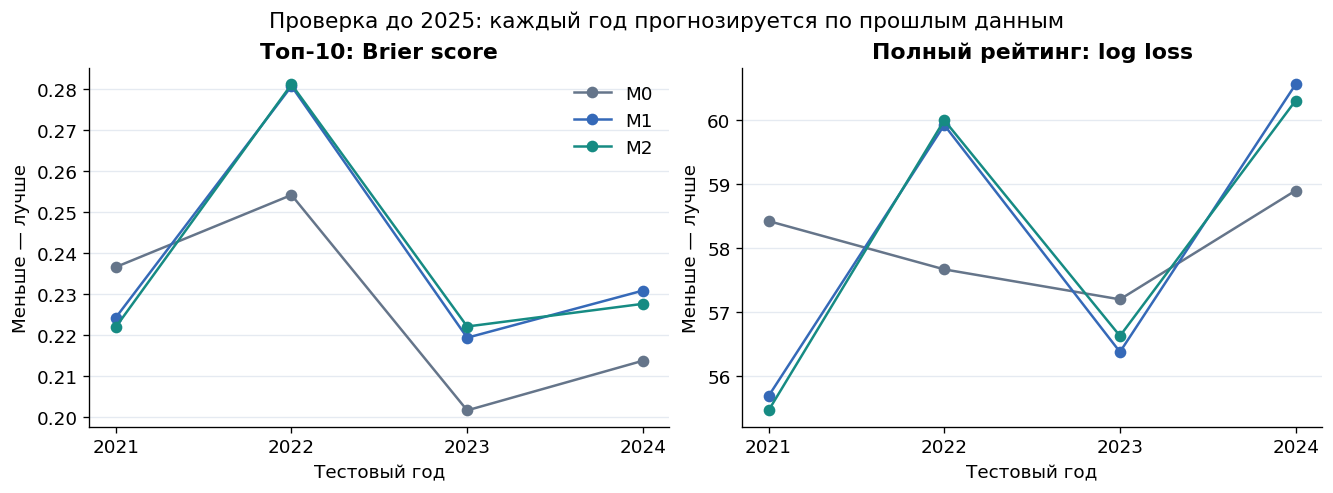

,comparison,metric,mean_difference,q025,q975,n_years
0,M1 − M0,brier,0.0123,-0.0048,0.0242,4
1,M2 − M1,brier,-0.0006,-0.0028,0.0016,4
2,M1 − M0,ranking_log_loss,0.0899,-1.7776,1.9574,4
3,M2 − M1,ranking_log_loss,-0.0383,-0.2391,0.1626,4


Отрицательная разница — улучшение. Интервалы ресемплируют целые годы; при четырёх годах они ориентировочные.


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for model_id in MODELS:
    g = dev_metrics.loc[dev_metrics.model.eq(model_id)]
    for ax, metric in zip(axes, ["brier", "ranking_log_loss"]):
        ax.plot(g.year, g[metric], "o-", label=model_id, color=COLORS[model_id])
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.grid(axis="y", color="#E5EAF1")
axes[0].set(title="Топ-10: Brier score", xlabel="Тестовый год", ylabel="Меньше — лучше")
axes[1].set(title="Полный рейтинг: log loss", xlabel="Тестовый год", ylabel="Меньше — лучше")
axes[0].legend(frameon=False)
fig.suptitle("Проверка до 2025: каждый год прогнозируется по прошлым данным", fontsize=13)
fig.savefig(OUTPUT_DIR / "development_scores.png", dpi=200, bbox_inches="tight")
plt.show()

paired_rows = []
for metric in ["brier", "ranking_log_loss"]:
    pivot = dev_metrics.pivot(index="year", columns="model", values=metric)
    for newer, older in [("M1", "M0"), ("M2", "M1")]:
        delta = (pivot[newer] - pivot[older]).to_numpy()
        rng = np.random.default_rng(SEED)
        bootstrap = rng.choice(delta, size=(10_000, len(delta)), replace=True).mean(axis=1)
        lo, hi = np.quantile(bootstrap, [0.025, 0.975])
        paired_rows.append(dict(comparison=f"{newer} − {older}", metric=metric,
                                mean_difference=delta.mean(), q025=lo, q975=hi,
                                n_years=len(delta)))
paired_comparisons = pd.DataFrame(paired_rows)
display(paired_comparisons.round(4))
print("Отрицательная разница — улучшение. Интервалы ресемплируют целые годы; при четырёх годах они ориентировочные.")


## 8. Чувствительность к priors

На последнем году **до 2025** повторяем расчёт с удвоенными масштабами priors.
Это проверка устойчивости, а не подбор priors по финальному тесту.
Основной прогноз 2025 сохраняет исходную спецификацию.


In [14]:
sensitivity_rows = []
if RUN_SENSITIVITY:
    year = DEV_YEARS[-1]
    train = development.loc[development.year.lt(year)]
    design = development.loc[development.year.eq(year), ["year", "country"] + FEATURES]
    truth = development.loc[development.year.eq(year),
                            ["year", "country", "place_final", "target_top10"]]
    for i, model_id in enumerate(MODELS):
        run = run_year(model_id, train, design, SEED + year * 10 + i, prior_multiplier=2.0)
        row = score_forecast(run["prediction"], run["eta"], truth)
        row["prior_scale"] = "2x"
        sensitivity_rows.append(row)
        diagnostics.append(run["diagnostic"] | {"prior_scale": "2x"})
    base = dev_metrics.loc[dev_metrics.year.eq(year)].assign(prior_scale="1x")
    sensitivity = pd.concat([base, pd.DataFrame(sensitivity_rows)], ignore_index=True)
    display(sensitivity[["model", "prior_scale", "brier", "ranking_log_loss"]].round(4))


  M0: NUTS, попытка 1


sample: 100%|██████████| 2000/2000 [00:04<00:00, 469.92it/s, 15 steps of size 2.78e-01. acc. prob=0.96]


  {'model': 'M0', 'year': 2024, 'prior_multiplier': 2.0, 'train_start': 2015, 'train_end': 2023, 'rhat_max': 1.00479, 'ess_bulk_min': 4951.471543, 'ess_tail_min': 2280.373979, 'divergences': 0, 'max_depth_hits': 0, 'seconds': 24.681040824000092, 'attempt': 1, 'passed': True}
  M1: NUTS, попытка 1


sample: 100%|██████████| 2000/2000 [00:06<00:00, 300.43it/s, 15 steps of size 2.46e-01. acc. prob=0.95]


  {'model': 'M1', 'year': 2024, 'prior_multiplier': 2.0, 'train_start': 2015, 'train_end': 2023, 'rhat_max': 1.002914, 'ess_bulk_min': 2174.185662, 'ess_tail_min': 2051.322725, 'divergences': 0, 'max_depth_hits': 0, 'seconds': 31.273829041, 'attempt': 1, 'passed': True}
  M2: NUTS, попытка 1


sample: 100%|██████████| 2000/2000 [00:07<00:00, 253.07it/s, 15 steps of size 2.41e-01. acc. prob=0.94]


  {'model': 'M2', 'year': 2024, 'prior_multiplier': 2.0, 'train_start': 2015, 'train_end': 2023, 'rhat_max': 1.005211, 'ess_bulk_min': 640.37425, 'ess_tail_min': 945.859404, 'divergences': 0, 'max_depth_hits': 0, 'seconds': 39.99634253399995, 'attempt': 1, 'passed': True}


,model,prior_scale,brier,ranking_log_loss
0,M0,1x,0.2138,58.8985
1,M1,1x,0.2309,60.5579
2,M2,1x,0.2276,60.3040
3,M0,2x,0.2176,61.0867
4,M1,2x,0.2403,62.7623
5,M2,2x,0.2317,61.2165


## 9. Финальный тест: 2025

Фиксируем исходные модели, обучаемся на годах до 2025 и выпускаем прогноз.
Только после этого присоединяем фактические места.
Сравниваем вероятность реального победителя, его прогнозное место и ошибки топ-10.


In [15]:
holdout_runs, holdout_scores = {}, []

for i, model_id in enumerate(MODELS):
    print(f"\nФинальный тест 2025: {model_id}", flush=True)

    # Уже рассчитанный posterior подхватится из кэша.
    run = run_year(
        model_id, development, holdout_design,
        SEED + HOLDOUT_YEAR * 10 + i
    )
    holdout_runs[model_id] = run
    diagnostics.append(run["diagnostic"])

    pred, eta = run["prediction"], run["eta"]
    joined = pred.merge(
        holdout_truth,
        on=["year", "country"],
        validate="one_to_one"
    )

    y = joined.target_top10.to_numpy(float)
    p_raw = joined.p_top10.to_numpy(float)
    p = np.clip(p_raw, 1e-12, 1 - 1e-12)

    # Совместная вероятность фактического полного рейтинга.
    positions = (
        holdout_truth.set_index("country")
        .loc[pred.country, "place_final"]
        .to_numpy()
    )
    ranked_eta = eta[..., np.argsort(positions)]
    logp = np.asarray(
        pl_log_prob(
            jnp.asarray(ranked_eta),
            jnp.ones_like(ranked_eta, dtype=bool)
        )
    )
    assert np.isfinite(logp).all(), "Некорректные вероятности рейтинга"

    ranking_loss_estimate = float(
        -(logsumexp(logp) - np.log(logp.size))
    )

    # Проверяем вычислительную точность дополнительной метрики.
    relative_likelihood = np.exp(logp - logp.max())
    mcse_result = az.mcse(
        az.from_dict(
            posterior={"likelihood": relative_likelihood}
        ),
        method="mean"
    )
    ranking_mcse = float(
        mcse_result.likelihood.values
        / relative_likelihood.mean()
    )
    ranking_reliable = bool(
        np.isfinite(ranking_mcse) and ranking_mcse <= 0.5
    )

    if not ranking_reliable:
        print(
            f"{model_id}: log loss полного рейтинга оценён "
            f"недостаточно точно (MCSE={ranking_mcse:.3f}). "
            "В таблице будет NaN. Остальные метрики сохраняются.",
            flush=True
        )

    winner = joined.loc[joined.place_final.eq(1)].iloc[0]
    winner_mask = joined.place_final.eq(1).to_numpy()
    predicted_ranks = rankdata(
        -joined.p_win.to_numpy(), method="min"
    )

    holdout_scores.append({
        "model": model_id,
        "year": HOLDOUT_YEAR,
        "brier": float(np.mean((p_raw - y) ** 2)),
        "binary_log_loss": float(
            -np.mean(y * np.log(p) + (1 - y) * np.log1p(-p))
        ),
        "ranking_log_loss": (
            ranking_loss_estimate if ranking_reliable else np.nan
        ),
        "ranking_log_loss_mcse": ranking_mcse,
        "ranking_log_loss_reliable": ranking_reliable,
        "winner_log_loss": float(-np.log(winner.p_win)),
        "p_actual_winner": float(winner.p_win),
        "winner_predicted_rank": int(
            predicted_ranks[winner_mask][0]
        ),
    })

holdout_metrics = (
    pd.DataFrame(holdout_scores).set_index("model")
)

predictions_2025 = pd.concat(
    [r["prediction"] for r in holdout_runs.values()],
    ignore_index=True
)
comparison_2025 = predictions_2025.merge(
    holdout_truth,
    on=["year", "country"],
    validate="many_to_one"
)

actual_winner = holdout_truth.loc[
    holdout_truth.place_final.eq(1), "country"
].item()

display(Markdown(
    f"**Фактический победитель 2025: {actual_winner}.** "
    "Прогнозы рассчитаны без обучения на результатах 2025."
))
display(holdout_metrics.round(4))

table_2025 = comparison_2025.pivot(
    index="country",
    columns="model",
    values=["p_win", "p_top10"]
)
table_2025.columns = [
    f"{model}_{metric}"
    for metric, model in table_2025.columns
]
table_2025 = table_2025.join(
    holdout_truth.set_index("country").place_final
).sort_values("place_final")

display(
    table_2025.style.format({
        col: "{:.1%}"
        for col in table_2025.columns
        if col != "place_final"
    })
)


Финальный тест 2025: M0
  M0: NUTS, попытка 1


sample: 100%|██████████| 2000/2000 [00:04<00:00, 449.10it/s, 15 steps of size 3.18e-01. acc. prob=0.95]


  {'model': 'M0', 'year': 2025, 'prior_multiplier': 1.0, 'train_start': 2015, 'train_end': 2024, 'rhat_max': 1.005258, 'ess_bulk_min': 8648.493148, 'ess_tail_min': 2150.519435, 'divergences': 0, 'max_depth_hits': 0, 'seconds': 34.25424116099998, 'attempt': 1, 'passed': True}

Финальный тест 2025: M1
  M1: NUTS, попытка 1


sample: 100%|██████████| 2000/2000 [00:07<00:00, 266.35it/s, 15 steps of size 2.42e-01. acc. prob=0.96]


  {'model': 'M1', 'year': 2025, 'prior_multiplier': 1.0, 'train_start': 2015, 'train_end': 2024, 'rhat_max': 1.00481, 'ess_bulk_min': 3391.771447, 'ess_tail_min': 2432.938363, 'divergences': 0, 'max_depth_hits': 0, 'seconds': 33.73988053999983, 'attempt': 1, 'passed': True}

Финальный тест 2025: M2
  M2: NUTS, попытка 1


sample: 100%|██████████| 2000/2000 [00:10<00:00, 192.76it/s, 31 steps of size 1.88e-01. acc. prob=0.95]


  {'model': 'M2', 'year': 2025, 'prior_multiplier': 1.0, 'train_start': 2015, 'train_end': 2024, 'rhat_max': 1.005531, 'ess_bulk_min': 664.221768, 'ess_tail_min': 1164.278009, 'divergences': 0, 'max_depth_hits': 0, 'seconds': 50.12316454399979, 'attempt': 1, 'passed': True}


**Фактический победитель 2025: AT.** Прогнозы рассчитаны без обучения на результатах 2025.

,year,brier,binary_log_loss,ranking_log_loss,ranking_log_loss_mcse,ranking_log_loss_reliable,winner_log_loss,p_actual_winner,winner_predicted_rank
model,,,,,,,,,
M0,2025,0.2036,0.5929,59.6936,0.0770,True,3.6568,0.0258,23
M1,2025,0.2080,0.6059,61.0323,0.0747,True,4.5598,0.0105,25
M2,2025,0.2055,0.6040,60.9196,0.1193,True,4.5247,0.0108,25


,M0_p_win,M1_p_win,M2_p_win,M0_p_top10,M1_p_top10,M2_p_top10,place_final
country,,,,,,,
AT,2.6%,1.0%,1.1%,29.2%,14.2%,14.2%,1
IL,3.7%,5.9%,6.4%,39.2%,57.5%,59.0%,2
EE,4.0%,2.1%,2.1%,41.3%,26.3%,25.9%,3
SE,8.8%,14.1%,12.0%,68.2%,84.7%,79.1%,4
IT,8.7%,11.8%,11.2%,67.4%,80.3%,78.3%,5
GR,3.6%,4.1%,4.6%,37.8%,45.3%,48.5%,6
FR,3.2%,4.9%,5.4%,35.2%,51.1%,53.9%,7
AL,3.0%,2.5%,2.4%,33.4%,30.9%,29.1%,8
UA,4.8%,4.3%,4.6%,47.1%,46.1%,47.3%,9


## 10. Прогноз и фактический результат

Страны упорядочены по прогнозу M2 на топ-10. Рядом указано фактическое место;
победитель выделен. Левая панель — общая победа, правая — топ-10.
Совпадение с фактическим победителем — один пример; основная оценка опирается
также на предыдущие годы и вероятностные ошибки.


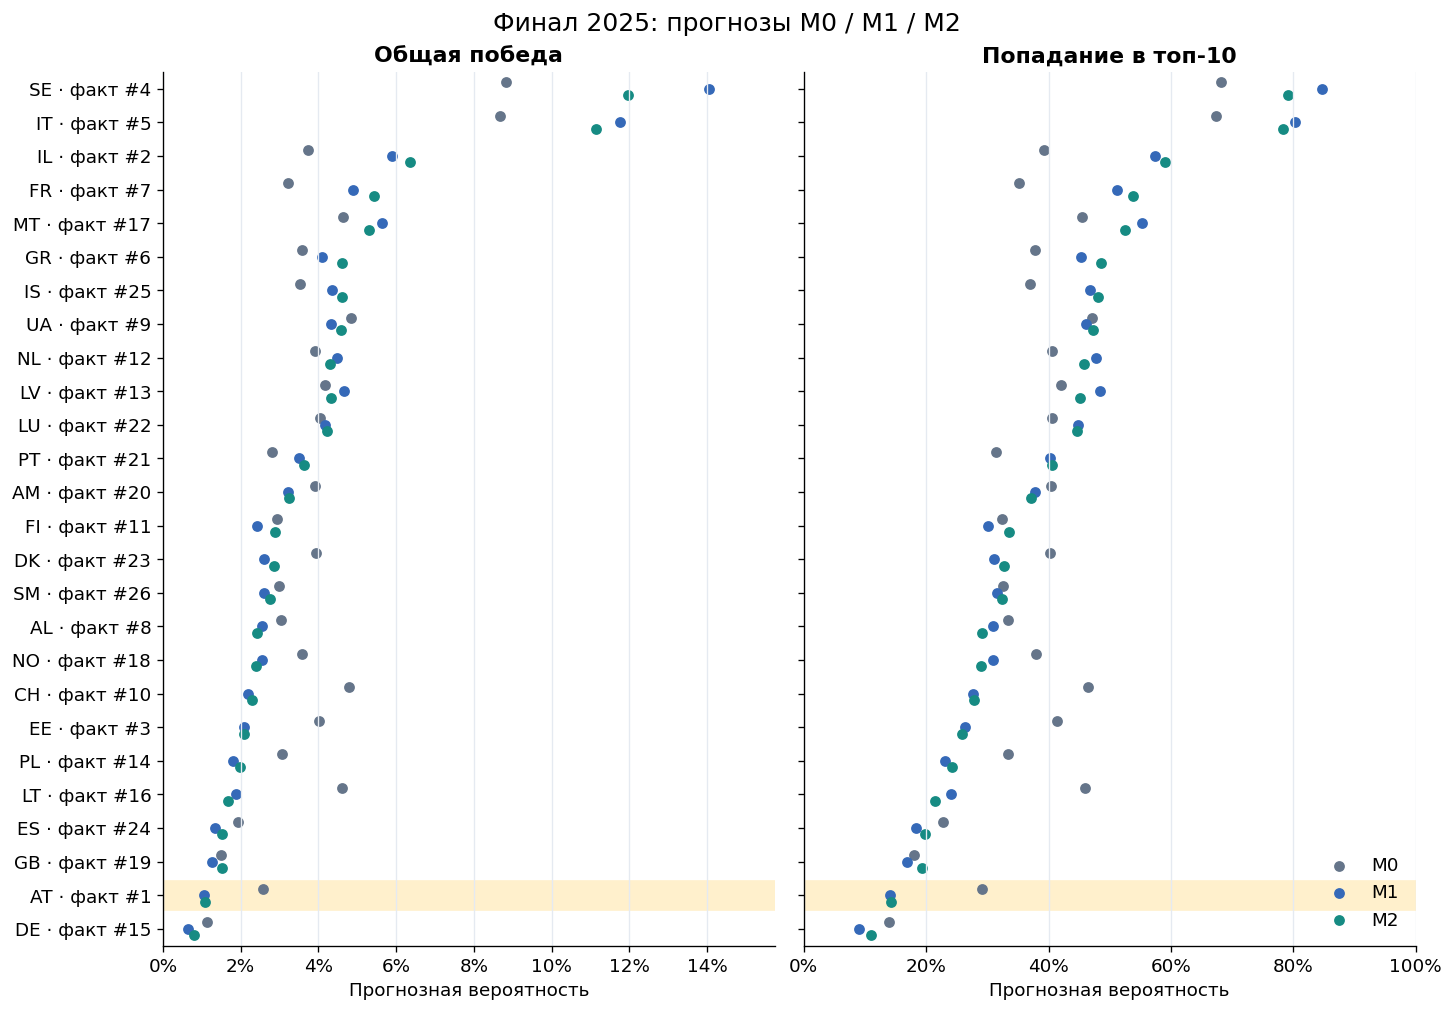

In [16]:
country_order = holdout_runs["M2"]["prediction"].sort_values("p_top10", ascending=False).country.tolist()
actual_ranks = holdout_truth.set_index("country").place_final
y = np.arange(len(country_order))
fig, axes = plt.subplots(1, 2, figsize=(12, max(7, len(y)*0.32)), sharey=True, layout="constrained")
for i, model_id in enumerate(MODELS):
    p = holdout_runs[model_id]["prediction"].set_index("country").loc[country_order]
    for ax, col in zip(axes, ["p_win", "p_top10"]):
        ax.scatter(p[col], y + (i-1)*0.19, s=30, color=COLORS[model_id], label=model_id)
        ax.grid(axis="x", color="#E5EAF1")
        ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
winner_row = country_order.index(actual_winner)
for ax in axes:
    ax.axhspan(winner_row-0.43, winner_row+0.43, color="#FFF0CC", zorder=-1)
    ax.set_ylim(len(y)-0.5, -0.5)
    ax.set_xlabel("Прогнозная вероятность")
axes[0].set_yticks(y, [f"{c} · факт #{actual_ranks[c]}" for c in country_order])
axes[0].set_title("Общая победа")
axes[1].set_title("Попадание в топ-10")
axes[0].set_xlim(0, max(0.10, predictions_2025.p_win.max()*1.12))
axes[1].set_xlim(0, 1)
axes[1].legend(frameon=False, loc="lower right")
fig.suptitle("Финал 2025: прогнозы M0 / M1 / M2", fontsize=15)
fig.savefig(OUTPUT_DIR / "forecast_2025.png", dpi=240, bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "forecast_2025.pdf", bbox_inches="tight")
plt.show()


## Диагностика финальных расчётов

Численная проверка дополнена trace plots силы одной и той же страны.
Для M2 отдельно показываем оцениваемый масштаб различий между странами.


,model,train_end,rhat_max,ess_bulk_min,ess_tail_min,divergences,passed
0,M0,2024,1.0053,8648.4931,2150.5194,0,True
1,M1,2024,1.0048,3391.7714,2432.9384,0,True
2,M2,2024,1.0055,664.2218,1164.2780,0,True


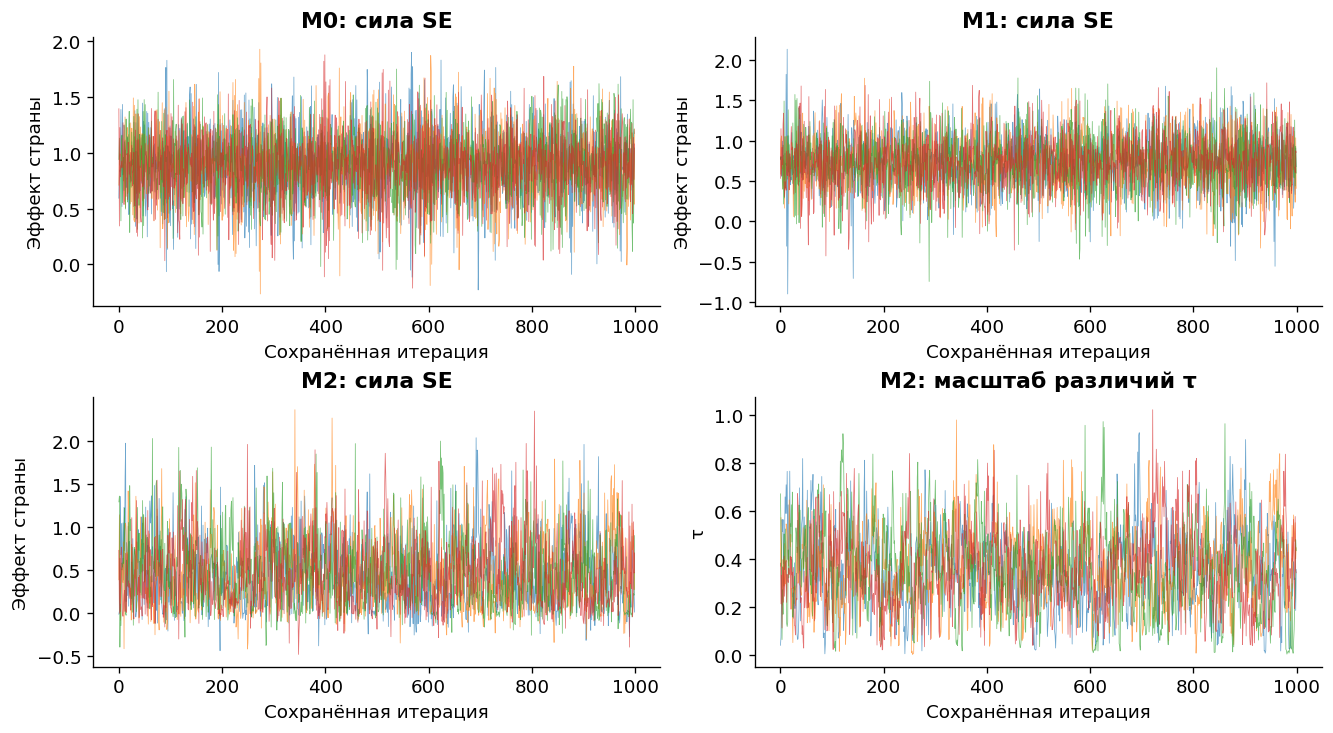

In [17]:
display(pd.DataFrame([r["diagnostic"] for r in holdout_runs.values()])[
    ["model", "train_end", "rhat_max", "ess_bulk_min", "ess_tail_min", "divergences", "passed"]])
trace_country = "SE" if "SE" in holdout_runs["M0"]["fold"]["index"] else holdout_runs["M0"]["fold"]["countries"][0]
fig, axes = plt.subplots(2, 2, figsize=(11, 6), layout="constrained")
for ax, model_id in zip(axes.flat, MODELS):
    r = holdout_runs[model_id]
    j = r["fold"]["index"][trace_country]
    for chain in r["samples"]["a"][:, :, j]:
        ax.plot(chain, linewidth=0.45, alpha=0.65)
    ax.set(title=f"{model_id}: сила {trace_country}", xlabel="Сохранённая итерация", ylabel="Эффект страны")
for chain in holdout_runs["M2"]["samples"]["tau"]:
    axes[1, 1].plot(chain, linewidth=0.45, alpha=0.65)
axes[1, 1].set(title="M2: масштаб различий τ", xlabel="Сохранённая итерация", ylabel="τ")
fig.savefig(OUTPUT_DIR / "posterior_traces.png", dpi=180, bbox_inches="tight")
plt.show()


## 11. Калибровка до 2025

Сопоставляем прогноз топ-10 с частотой попаданий. Используем фиксированные
интервалы вероятностей, как в HA1. Каждый конкурс имеет одинаковый суммарный вес.
При малом числе конкурсов этот график — описательная проверка.


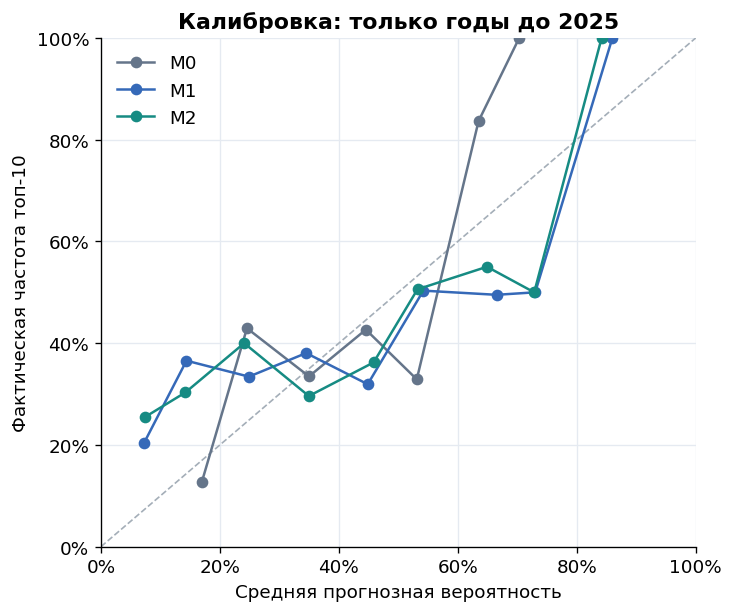

In [18]:
fig, ax = plt.subplots(figsize=(6, 5), layout="constrained")
ax.plot([0, 1], [0, 1], "--", color="#A4AEB8", linewidth=1)
calibration_tables = []
for model_id in MODELS:
    rows = []
    for year in DEV_YEARS:
        pred = development_runs[(year, model_id)]["prediction"]
        truth = development.loc[development.year.eq(year), ["year", "country", "target_top10"]]
        rows.append(pred.merge(truth, on=["year", "country"]).assign(weight=1/len(pred)))
    p = pd.concat(rows, ignore_index=True)
    p["bin"] = pd.cut(p.p_top10, np.linspace(0, 1, 11), include_lowest=True, right=True)
    bins = []
    for interval, g in p.groupby("bin", observed=True):
        bins.append(dict(model=model_id, bin=str(interval), n=len(g),
                         predicted=np.average(g.p_top10, weights=g.weight),
                         observed=np.average(g.target_top10, weights=g.weight)))
    bins = pd.DataFrame(bins)
    calibration_tables.append(bins)
    ax.plot(bins.predicted, bins.observed, "o-", color=COLORS[model_id], label=model_id)
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Средняя прогнозная вероятность",
       ylabel="Фактическая частота топ-10", title="Калибровка: только годы до 2025")
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.grid(color="#E5EAF1")
ax.legend(frameon=False)
fig.savefig(OUTPUT_DIR / "calibration_development.png", dpi=200, bbox_inches="tight")
plt.show()


## 12. Сохранение и выводы

Сохраняем вероятности, ошибки, диагностику, стандартизацию и posterior draws.
`mcse_top10` — вычислительная погрешность, а не доверительный интервал прогноза.
`ranking_log_loss_mcse` — приближённая вычислительная погрешность log loss рейтинга;
различия меньше этой погрешности сами по себе не подтверждают преимущество модели.
Интервалы `rank_q05/rank_q95` описывают неопределённость будущего места.
Коэффициенты отражают прогностические связи, не причинные эффекты.
Не объявляем сложную модель лучшей автоматически: смотрим на сравнение ошибок.


In [19]:
dev_predictions = pd.concat([r["prediction"] for r in development_runs.values()], ignore_index=True)
dev_predictions.to_csv(OUTPUT_DIR / "development_predictions.csv", index=False)
dev_metrics.to_csv(OUTPUT_DIR / "development_metrics_by_year.csv", index=False)
dev_summary.to_csv(OUTPUT_DIR / "development_summary.csv")
paired_comparisons.to_csv(OUTPUT_DIR / "paired_comparisons.csv", index=False)
predictions_2025.to_csv(OUTPUT_DIR / "predictions_2025.csv", index=False)
comparison_2025.to_csv(OUTPUT_DIR / "comparison_2025.csv", index=False)
holdout_metrics.to_csv(OUTPUT_DIR / "metrics_2025.csv")
pd.DataFrame(diagnostics).to_csv(OUTPUT_DIR / "diagnostics.csv", index=False)
prior_predictive.to_csv(OUTPUT_DIR / "prior_predictive.csv", index=False)
pd.concat(calibration_tables).to_csv(OUTPUT_DIR / "calibration.csv", index=False)
if sensitivity_rows:
    sensitivity.to_csv(OUTPUT_DIR / "prior_sensitivity_2024.csv", index=False)
scaler = pd.DataFrame({"mean": holdout_runs["M1"]["fold"]["mean"],
                       "scale": holdout_runs["M1"]["fold"]["scale"]})
scaler.to_csv(OUTPUT_DIR / "training_scaler_2025.csv")
country_effects, feature_effects = [], []
for model_id, run in holdout_runs.items():
    a = run["samples"]["a"].reshape(-1, len(run["fold"]["countries"]))
    for j, country in enumerate(run["fold"]["countries"]):
        country_effects.append(dict(model=model_id, country=country, mean=a[:, j].mean(),
                                    q05=np.quantile(a[:, j], 0.05), q95=np.quantile(a[:, j], 0.95)))
    if model_id != "M0":
        b = run["samples"]["beta"].reshape(-1, len(FEATURES))
        for j, feature in enumerate(FEATURES):
            feature_effects.append(dict(model=model_id, feature=feature, mean=b[:, j].mean(),
                                        q05=np.quantile(b[:, j], 0.05), q95=np.quantile(b[:, j], 0.95)))
pd.DataFrame(country_effects).to_csv(OUTPUT_DIR / "country_effects_2025.csv", index=False)
pd.DataFrame(feature_effects).to_csv(OUTPUT_DIR / "feature_effects_2025.csv", index=False)
manifest = dict(experiment=EXPERIMENT, sheet=SHEET, features=FEATURES, holdout=HOLDOUT_YEAR,
                development_test_years=[int(y) for y in DEV_YEARS],
                train_rule="year < test_year", seed=SEED, model_version=MODEL_VERSION,
                country_sd=COUNTRY_SD, beta_sd=BETA_SD, tau_sd=TAU_SD,
                chains=NUM_CHAINS, warmup=NUM_WARMUP, samples=NUM_SAMPLES,
                rankings_per_draw=RANKINGS_PER_DRAW,
                versions=dict(numpyro=numpyro.__version__, jax=jax.__version__, arviz=az.__version__),
                input_sha256=hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),
                market_snapshot_time="unknown_accepted" if EXPERIMENT=="market" else "not_used")
(OUTPUT_DIR / "manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")
for newer, older in [("M1", "M0"), ("M2", "M1")]:
    diff = dev_metrics.pivot(index="year", columns="model", values="brier")
    delta = float((diff[newer] - diff[older]).mean())
    print(f"До 2025: Brier({newer}) − Brier({older}) = {delta:+.4f}; отрицательное значение — улучшение.")
for model_id, r in holdout_runs.items():
    p = r["prediction"]
    favorite = p.loc[p.p_win.idxmax()]
    print(f"{model_id}: фаворит {favorite.country}, P(победы)={favorite.p_win:.1%}; "
          f"факт-победитель {actual_winner}, P={holdout_metrics.loc[model_id, 'p_actual_winner']:.1%}.")
archive = shutil.make_archive(str(OUTPUT_DIR), "zip", OUTPUT_DIR)
print(f"Результаты: {OUTPUT_DIR.resolve()}\nАрхив: {archive}")


До 2025: Brier(M1) − Brier(M0) = +0.0123; отрицательное значение — улучшение.
До 2025: Brier(M2) − Brier(M1) = -0.0006; отрицательное значение — улучшение.
M0: фаворит SE, P(победы)=8.8%; факт-победитель AT, P=2.6%.
M1: фаворит SE, P(победы)=14.1%; факт-победитель AT, P=1.0%.
M2: фаворит SE, P(победы)=12.0%; факт-победитель AT, P=1.1%.
Результаты: /content/results_A/matched_core
Архив: /content/results_A/matched_core.zip


## Основа в материалах курса

HA1 — Brier и калибровка; HA2 — prior/posterior/predictive и хронологическое обновление;
HA3 — интегрирование вероятностей по posterior и устойчивый log score;
HA4 — NumPyro/NUTS, нецентрированная иерархия. Plackett–Luce — адаптация модели выбора
к полному рейтингу, а не готовая модель из домашнего задания.
API: [NumPyro MCMC](https://num.pyro.ai/en/stable/mcmc.html),
[ArviZ summary](https://python.arviz.org/en/v0.22.0/api/generated/arviz.summary.html).
